# Bertrand paradox

Lecture 02 of the SAED course

What is the probability that the length of a random chord is greater than the side of the equilateral triangle inscribed in a circle?

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.patches import Circle
from matplotlib.collections import LineCollection


There are many ways to define a line in (X,Y) plane. One can specify two end-points A and B, which require giving four coordinates:  $(x_A, y_A)$ and $(x_B, y_B)$. But one can also specify the line by giving its distance $d$ from the center of the coordinate system $(0,0)$ and the asimuthal angle of the point of the closes approach $\phi$. Equation of the line is then given by: 
$$ x \cdot \cos\phi \; + \; y \cdot \sin\phi \; = \; d $$
Each line, when crossing the circle, defines the chord, so we can also describe each chord in terms of $d$ and $\phi$ parameters.

In [2]:
# Get line/chord parameters from two points
# We do not check if d is positive, but it has no influence on the result

def getchord(x1,y1,x2,y2):

    phi = np.atan2(x2-x1,y1-y2)

    d   =  x1 * np.cos(phi) + y1 * np.sin(phi)
    
    return d,phi

In [3]:
# Get chord endpoints
# Consider only points inside the circle (!)

def getpoints(d,phi):

    d1 = 1-d*d
    isgood = d1 > 0

    gd = d[isgood]
    gphi = phi[isgood]
    g1 = np.sqrt(1-gd*gd)
    
    x1 =  gd*np.cos(gphi) - g1*np.sin(gphi)
    y1 =  gd*np.sin(gphi) + g1*np.cos(gphi)
    
    x2 =  gd*np.cos(gphi) + g1*np.sin(gphi)
    y2 =  gd*np.sin(gphi) - g1*np.cos(gphi)

    points = np.array([x1 , y1, x2, y2])    # Two points 
    
    endpoints = points.transpose().reshape(x1.size,2,2)

    return endpoints


In [4]:
# Function to check lenght criteria

def lencheck(d):

    # Lines crossing the circle

    isgood = d*d < 1
    Ngood = np.sum(isgood)

    # Chord lenght squared 
    
    len2 = 4*(1 - d*d)

    # Triangle side is sqrt(3), but we compare lenght squared
    islonger =  len2 >  3
    
    frac = np.sum(islonger)/Ngood
    dfrac = np.sqrt(frac*(1-frac)/Ngood)
    
    print(f"Fraction of chords longer than triangle side: {frac:.5f} +/- {dfrac:.5f}")

In [5]:

def chplot(d,phi,figname='02_bertrand.png',Nplot=1000):

    lines = getpoints(d,phi)
    
    # Create the figure and axes
    fig, ax = plt.subplots(figsize=(6, 6))
    
    # Set limits so the entire circle is visible (slightly larger than the radius)
    ax.set_xlim(-1.05, 1.05)
    ax.set_ylim(-1.05, 1.05)
    
    # Set equal aspect ratio
    ax.set_aspect('equal')
    
    # Remove axis
    ax.axis('off')
    
    #-------------------------------------------------------------------------------
    # Create a circle 
    circle = Circle(xy=(0, 0), radius=1, linewidth=4, edgecolor='blue', fill=False)
    
    # Add the circle to the axes
    ax.add_patch(circle)
    
    #------------------------------------------------------------------------------
    # draw chords
    
    lc = LineCollection(lines[:Nplot], colors='red', linewidths=2, alpha=0.2)
    
    # Add the collection to the axis
    ax.add_collection(lc)
    
    #
    #------------------------------------------------------------------------------
    # Display the plot
    
    plt.savefig(figname)
    
    plt.show()

In [6]:
# Generation of random chords

Nch = 100000

### Solution 1

Random chord is defined as connecting two random points on the circle

Fraction of chords longer than triangle side: 0.33295 +/- 0.00149


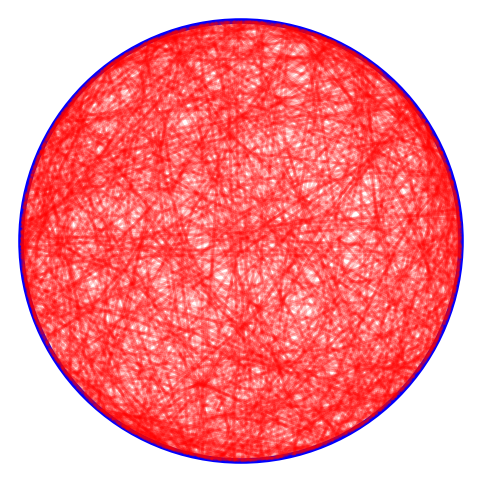

In [7]:
# Solution 1

phich = 2*np.pi * np.random.rand(Nch,2)         # Two random phi angles per chord

# First point on the unit circle
x1 = np.cos(phich[:,0])
y1 = np.sin(phich[:,0])

# Second point
x2 = np.cos(phich[:,1])
y2 = np.sin(phich[:,1])

d,phi = getchord(x1,y1,x2,y2)

lencheck(d)

# Plot name
fname = '02_bertrand_1.png'

chplot(d,phi,fname)

### Solution 2

Random chord is defined by a random point on the cicle radius as its center (plus random rotation) 

Fraction of chords longer than triangle side: 0.49941 +/- 0.00158


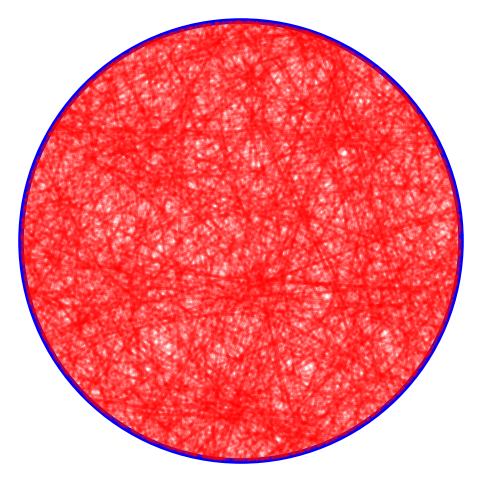

In [8]:
# Solution 2

rd = np.random.rand(Nch)                     # Random distance from center
rphi = 2*np.pi * np.random.rand(Nch)         # Random phi angle

lencheck(rd)

# Plot name
fname = '02_bertrand_2.png'

chplot(rd,rphi,fname)

### Solution 3

Random point inside the circle is taken as the centre of the chord (its point of closest approach)

Fraction of chords longer than triangle side: 0.25090 +/- 0.00155


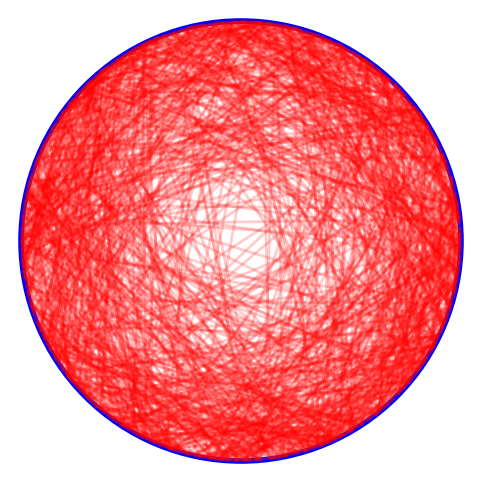

In [10]:
# Solution 3

x0 = 2*np.random.rand(Nch) - 1                 # Random point inside 2x2 square (covering the circle)
y0 = 2*np.random.rand(Nch) - 1 

rd = np.sqrt(x0*x0 + y0*y0)
rphi = np.atan2(y0,x0)              

# Lenght check (only lines crossing the circle are taken into account!)

lencheck(rd)

# Plot name
fname = '02_bertrand_3.png'

# Only lines crossing the circle are ploted!

chplot(rd,rphi,fname)